# Amplitude estimation with an explicit threshold predicate

This notebook constructs the whole phase-estimation algorithm, including a reversible threshold flag, preparation/inverse preparation, reflections and controlled powers. The threshold probability has a known classical answer; this is an implementation check, with no application-advantage claim. Install the public code bundle and pinned environment, or use the source checkout. Static pages reuse outputs; live controls require a local/Binder kernel.

In [1]:
from pathlib import Path
import sys
import math
import os
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd()
if not (root / "src").exists() and (root.parent / "src").exists():
    root = root.parent
if (root / "src").exists():
    sys.path.insert(0, str(root / "src"))
from openquantum.amplitude_estimation import (
    threshold_preparation, build_amplitude_estimation,
    simulate_amplitude_estimation, analytic_amplitude_distribution,
    decode_amplitude, amplitude_workload, exact_median_interval_failure,
)
from openquantum.qft_qpe import lower_circuit
n_data, threshold, phase_bits = 2, 1, 4
amplitude = threshold / 2**n_data

## Prepare a flagged uniform register

Data `q[0]` is the least significant bit; `q[n_data]` is the flag. Disjoint comparator prefix terms toggle the flag precisely when `x < threshold`. Its inverse is part of every amplification query.

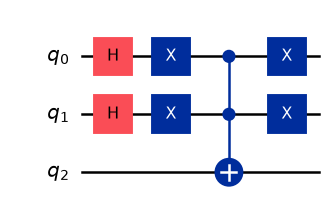

In [2]:
preparation = threshold_preparation(n_data, threshold)
preparation.draw(output="mpl", fold=40, scale=.9)

## Actual controlled Grover calls and inverse QFT

The minus sign in `Q=-A S0 A† Sgood` is retained under coherent control. Every power is expanded into repeated actual Q calls. Only the phase register is measured; the data/flag are discarded.

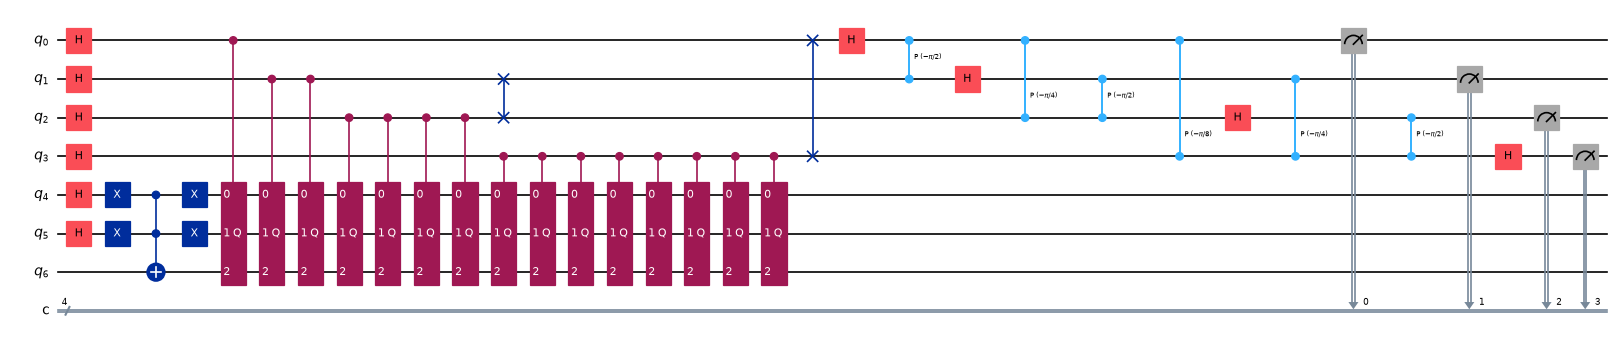

In [3]:
measured = build_amplitude_estimation(n_data, threshold, phase_bits, measure=True)
measured.draw(output="mpl", fold=45, scale=.6)

In [4]:
probabilities = simulate_amplitude_estimation(n_data, threshold, phase_bits)
reference = analytic_amplitude_distribution(amplitude, phase_bits)
np.testing.assert_allclose(probabilities, reference, atol=2e-12, rtol=0)
estimates = np.array([decode_amplitude(y, phase_bits) for y in range(2**phase_bits)])
print({"exact_amplitude": amplitude,
       "maximum_distribution_error": float(np.max(np.abs(probabilities-reference))),
       "most_likely_outcomes": np.flatnonzero(probabilities >= probabilities.max()-1e-12).tolist(),
       "mean_decoded_estimate": float(probabilities @ estimates)})

{'exact_amplitude': 0.25, 'maximum_distribution_error': 3.7192471324942744e-14, 'most_likely_outcomes': [3, 13], 'mean_decoded_estimate': 0.29687499999996925}


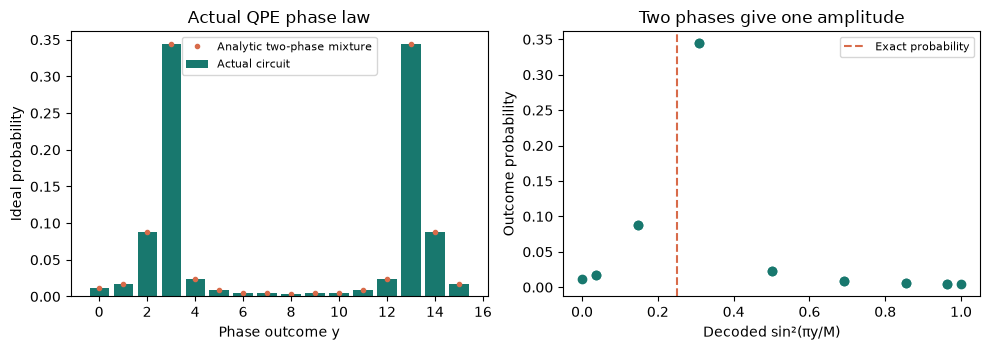

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].bar(range(2**phase_bits), probabilities, color="#18786e", label="Actual circuit")
axes[0].plot(range(2**phase_bits), reference, ".", color="#d86b4a", label="Analytic two-phase mixture")
axes[0].set(xlabel="Phase outcome y", ylabel="Ideal probability", title="Actual QPE phase law")
axes[0].legend(fontsize=8)
axes[1].scatter(estimates, probabilities, color="#18786e")
axes[1].axvline(amplitude, color="#d86b4a", linestyle="--", label="Exact probability")
axes[1].set(xlabel="Decoded sin²(πy/M)", ylabel="Outcome probability", title="Two phases give one amplitude")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## Confidence includes full independent circuit runs

The ideal BHMT bound plus a binomial majority tail specifies an odd median workload. A classical categorical ensemble checks its behavior; these are draws from an exact statevector law, not executed device shots. Physical and synthesis allowances are separate.

In [6]:
workload = amplitude_workload(n_data, threshold, phase_bits, failure_probability=.005)
repetitions = workload["repetitions"]
epsilon = workload["absolute_amplitude_error_bound"]
rng = np.random.default_rng(8127)
ensembles = 10000
outcomes = rng.choice(2**phase_bits, size=(ensembles, repetitions), p=probabilities/probabilities.sum())
medians = np.median(estimates[outcomes], axis=1)
print({"ideal_absolute_error_bound": epsilon,
       "complete_runs_per_ensemble": repetitions,
       "conservative_ideal_median_failure_bound": workload["ideal_median_failure_bound"],
       "exact_ideal_interval_failure": exact_median_interval_failure(amplitude, phase_bits, repetitions, probabilities),
       "categorical_ensemble_failures": int(np.sum(np.abs(medians-amplitude)>epsilon)),
       "ensembles": ensembles, "seed": 8127,
       "hardware_execution": False,
       "all_run_predicate_or_inverse_calls": workload["all_runs"]["threshold_predicate_or_inverse_calls"]})

{'ideal_absolute_error_bound': 0.2349026830411174, 'complete_runs_per_ensemble': 15, 'conservative_ideal_median_failure_bound': 0.0029684634290533004, 'exact_ideal_interval_failure': 1.3150786963881757e-05, 'categorical_ensemble_failures': 0, 'ensembles': 10000, 'seed': 8127, 'hardware_execution': False, 'all_run_predicate_or_inverse_calls': 465}


In [7]:
compiled = lower_circuit(measured)
assert len(compiled.data) == 6426
print({"live_qubits": compiled.num_qubits,
       "complete_measured_primitive_operations": len(compiled.data),
       "dependency_depth": compiled.depth(),
       "gate_counts": dict(compiled.count_ops()),
       "classical_same_precision_workload": workload["classical_same_preparation_comparison"]})

{'live_qubits': 7, 'complete_measured_primitive_operations': 6426, 'dependency_depth': 5151, 'gate_counts': {'cx': 2529, 'rz': 1234, 't': 1083, 'tdg': 813, 'h': 504, 'rx': 210, 'ry': 47, 'measure': 4, 'x': 2}, 'classical_same_precision_workload': {'method': 'independent Bernoulli flag samples with Hoeffding bound', 'shots_required': 55, 'absolute_error_target': 0.2349026830411174, 'failure_probability': 0.005, 'preparation_A_calls': 55, 'final_flag_measurements': 55, 'timing_executed': False, 'classical_shortcut': 'threshold/2**n is known exactly; classical sampling comparison is pedagogical'}}


## Optional live exploration

Local/Binder controls regenerate real circuits at one to three data bits and two to four phase bits. The callback verifies the phase law every time. The static build deliberately omits inactive widgets.

In [8]:
def explore_amplitude(n_data, threshold, phase_bits):
    if not 1 <= n_data <= 3 or not 2 <= phase_bits <= 4:
        raise ValueError("Live controls are capped at 3 data bits and 4 phase bits")
    if not 0 <= threshold <= 2**n_data:
        raise ValueError("Threshold is outside the selected register")
    law = simulate_amplitude_estimation(n_data, threshold, phase_bits)
    reference = analytic_amplitude_distribution(threshold/2**n_data, phase_bits)
    np.testing.assert_allclose(law, reference, atol=2e-12, rtol=0)
    print({"exact_probability": threshold/2**n_data,
           "live_qubits": n_data+1+phase_bits,
           "controlled_Q_calls": 2**phase_bits-1,
           "max_analytic_error": float(np.max(np.abs(law-reference)))})
    fig, ax = plt.subplots(figsize=(7, 2.8))
    ax.bar(range(2**phase_bits), law, color="#18786e")
    ax.set(xlabel="Phase outcome", ylabel="Ideal probability")
    plt.show()

if os.environ.get("OPENQUANTUM_STATIC_BUILD") != "1":
    import ipywidgets as widgets
    data_control = widgets.IntSlider(value=2, min=1, max=3, description="Data bits", continuous_update=False)
    threshold_control = widgets.IntSlider(value=1, min=0, max=4, description="Threshold", continuous_update=False)
    phase_control = widgets.IntSlider(value=4, min=2, max=4, description="Phase bits", continuous_update=False)
    def resize_threshold(change):
        threshold_control.max = 2**change["new"]
    data_control.observe(resize_threshold, names="value")
    output = widgets.interactive_output(explore_amplitude,
              {"n_data":data_control,"threshold":threshold_control,"phase_bits":phase_control})
    display(widgets.VBox([data_control, threshold_control, phase_control, output]))

## References and limits

BHMT, *Quantum Amplitude Amplification and Estimation* (2002), Theorem 12. Original explicit implementation uses Qiskit core 2.6.2 (Apache-2.0), NumPy 2.5.4 and Matplotlib 3.11.2. Quantum advantage, a hardware confidence certificate, iterative amplitude interval inference and Lean proof integration are not established. See the chapter’s in-page analysis and verification for the complete conditional surface-code report and exclusions.